# CLEM validation: zero-D reactor and premixed flame

Two cases, each run with **pure PeleC** (no model) and with **PeleC + CLEM** (particle LEM lines,
CVODE reactor per element). Everything else is the same in both runs: MOL with one iteration,
`ReactorCvode` with `denseAJ_direct` (analytic Jacobian), 4 MPI ranks.

| case | what it tests | data |
|---|---|---|
| zero-D | chemistry of the elements, constant-volume energy, write-back of the species, pressure coupling | `zeroD/` |
| premixed flame | the above plus diffusion along the lines, splicing, inter-cell transport | `pmf/` |

CLEM setup (`Source/Clem/setup.H`): `n_lem = 12`, `react_lines = true`, `reactor_type = e_reactor_type`
(constant volume), `skip_covered = false`, `freeze_les_species = true`, `EnergyCoupling::LesPlusSubgrid`,
`anchor_line_energy = true`.

In [1]:
import re
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

HERE = Path(".")
ZEROD = HERE / "zeroD"
PMF = HERE / "pmf"

C_PELEC, C_CLEM, C_REF, C_NOSPEC = "#1f5ea6", "#d0602a", "0.6", "#2a9d5c"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## Helpers

* `parse_extrema` reads the per-step min/max that PeleC prints with `pelec.track_extrema = 1`
  (`pelec.extrema_spec_name = ALL` adds every species).
* `read_plotfile` reads level 0 of an AMReX plotfile (no yt needed) and averages over y.
* `clem_diagnostics` reads the per-step CLEM report of the line operators.

In [2]:
def parse_extrema(log):
    """{variable: array[(t, min, max)]} from the extrema monitor of a PeleC log."""
    pat = re.compile(r"TIME = (\S+) (\S+)\s+MIN = (\S+)\s+MAX = (\S+)")
    out = {}
    for line in open(log):
        m = pat.match(line.strip())
        if m:
            out.setdefault(m[2], []).append((float(m[1]), float(m[3]), float(m[4])))
    return {k: np.array(v) for k, v in out.items()}


def run_time(log):
    for line in open(log):
        if line.startswith("Run time w/o init"):
            return float(line.split("=")[1])


def read_plotfile(path):
    """Level 0 of an AMReX plotfile -> (time, x, {name: field averaged over y})."""
    path = Path(path)
    lines = (path / "Header").read_text().split("\n")
    nvar = int(lines[1])
    names = lines[2:2 + nvar]
    k = 2 + nvar
    dim, time = int(lines[k]), float(lines[k + 1])
    lo = [float(v) for v in lines[k + 3].split()]
    hi = [float(v) for v in lines[k + 4].split()]
    dom = [int(v) for v in re.findall(r"-?\d+", lines[k + 6])]
    nx, ny = dom[dim] - dom[0] + 1, dom[dim + 1] - dom[1] + 1
    data = np.zeros((nvar, nx, ny))
    cell_h = (path / "Level_0" / "Cell_H").read_text()
    for fname, off in re.findall(r"FabOnDisk: (\S+) (\d+)", cell_h):
        with open(path / "Level_0" / fname, "rb") as f:
            f.seek(int(off))
            head = f.readline().decode()
            box = re.search(r"\)\)\(\(([-\d]+),([-\d]+)\) \(([-\d]+),([-\d]+)\)", head)
            ilo, jlo, ihi, jhi = (int(v) for v in box.groups())
            ncomp = int(head.split()[-1])
            n = (ihi - ilo + 1) * (jhi - jlo + 1)
            arr = np.fromfile(f, dtype="<f8", count=n * ncomp).reshape(ncomp, jhi - jlo + 1, ihi - ilo + 1)
            data[:, ilo:ihi + 1, jlo:jhi + 1] = arr.transpose(0, 2, 1)
    x = lo[0] + (np.arange(nx) + 0.5) * (hi[0] - lo[0]) / nx
    return time, x, {nm: data[i].mean(axis=1) for i, nm in enumerate(names)}


def read_series(run_dir):
    return [read_plotfile(p) for p in sorted(Path(run_dir).glob("plt?????")) if p.is_dir()]


def clem_diagnostics(log, level=0):
    """Per-step sub-steps (mean, max), enthalpy drift and CVODE RHS evaluations of one level."""
    sub, drift, rhs = [], [], []
    pat_l = re.compile(rf"CLEM: level {level} lines advanced .* sub-steps max (\d+) mean (\S+),.*enthalpy drift (\S+)")
    pat_r = re.compile(rf"CLEM: level {level} reaction: (\d+) element sub-steps, RHS evaluations mean (\S+) max (\d+)")
    for line in open(log):
        if m := pat_l.search(line):
            sub.append((float(m[2]), int(m[1]))); drift.append(float(m[3]))
        elif m := pat_r.search(line):
            rhs.append((int(m[1]), float(m[2]), int(m[3])))
    return np.array(sub), np.array(drift), np.array(rhs)

## 1. Zero-D reactor

`Exec/RegTests/zeroD`: a periodic 4³ box at rest, H₂/O₂/N₂ (Y = 0.06/0.5/0.44), T₀ = 1000 K,
p₀ = 10 atm, LiDryer. Every cell is a constant-volume reactor; with a uniform field the lines stay
uniform, so diffusion and splicing do nothing and the comparison isolates the reactor and the coupling.
Fixed `dt = 1e-6 s` to `t = 0.4 ms` (400 steps). Reference: `cantera_soln` (shipped with the case,
sampled every 10 µs).

In [3]:
zp = parse_extrema(ZEROD / "pelec" / "run.log")
zc = parse_extrema(ZEROD / "clem" / "run.log")
ref = np.loadtxt(ZEROD / "cantera_soln", skiprows=1)   # t, T, Y_H2, Y_O2, Y_OH

print(f"{'variable':10s} {'max|CLEM-PeleC|':>16s} {'relative':>10s} {'final PeleC':>13s} {'final CLEM':>13s} {'cell spread':>12s}")
for v in ["Temp", "pressure", "density", "eint_e", "H2", "O2", "OH", "H2O", "sumYminus1"]:
    p, c = zp[v], zc[v]
    n = min(len(p), len(c))
    d = np.abs(c[:n, 1] - p[:n, 1])
    scale = np.max(np.abs(p[:n, 1]))
    spread = max(np.max(p[:n, 2] - p[:n, 1]), np.max(c[:n, 2] - c[:n, 1]))
    rel = d.max() / scale if scale > 1e-12 else float("nan")   # sumYminus1 is round-off
    print(f"{v:10s} {d.max():16.3e} {rel:10.2e} {p[n-1, 1]:13.6e} {c[n-1, 1]:13.6e} {spread:12.1e}")

variable    max|CLEM-PeleC|   relative   final PeleC    final CLEM  cell spread
Temp              4.000e-04   1.24e-07  3.223849e+03  3.223849e+03      0.0e+00
pressure          2.000e-01   7.04e-08  2.841996e+06  2.841996e+06      0.0e+00
density           0.000e+00   0.00e+00  1.994719e-04  1.994719e-04      0.0e+00
eint_e            9.000e+02   1.13e-07  7.993646e+09  7.993646e+09      0.0e+00
H2                3.000e-09   5.00e-08  1.091419e-02  1.091419e-02      0.0e+00
O2                4.000e-08   8.00e-08  7.143922e-02  7.143922e-02      0.0e+00
OH                1.900e-08   2.28e-07  8.335305e-02  8.335305e-02      0.0e+00
H2O               4.000e-08   1.09e-07  3.672846e-01  3.672846e-01      0.0e+00
sumYminus1        4.441e-16        nan  0.000000e+00  0.000000e+00      0.0e+00


In [4]:
def ignition_time(t, T, T_ign=1500.0):
    i = np.argmax(T > T_ign)
    return t[i - 1] + (T_ign - T[i - 1]) * (t[i] - t[i - 1]) / (T[i] - T[i - 1])

print("ignition time (T = 1500 K)")
print(f"  Cantera      {ignition_time(ref[:, 0], ref[:, 1]) * 1e3:.4f} ms")
print(f"  PeleC        {ignition_time(zp['Temp'][:, 0], zp['Temp'][:, 1]) * 1e3:.4f} ms")
print(f"  PeleC + CLEM {ignition_time(zc['Temp'][:, 0], zc['Temp'][:, 1]) * 1e3:.4f} ms")
print(f"\nrun time w/o init: PeleC {run_time(ZEROD / 'pelec' / 'run.log'):.1f} s, "
      f"PeleC + CLEM {run_time(ZEROD / 'clem' / 'run.log'):.1f} s")

ignition time (T = 1500 K)
  Cantera      0.1322 ms
  PeleC        0.1213 ms
  PeleC + CLEM 0.1213 ms

run time w/o init: PeleC 5.7 s, PeleC + CLEM 6.5 s


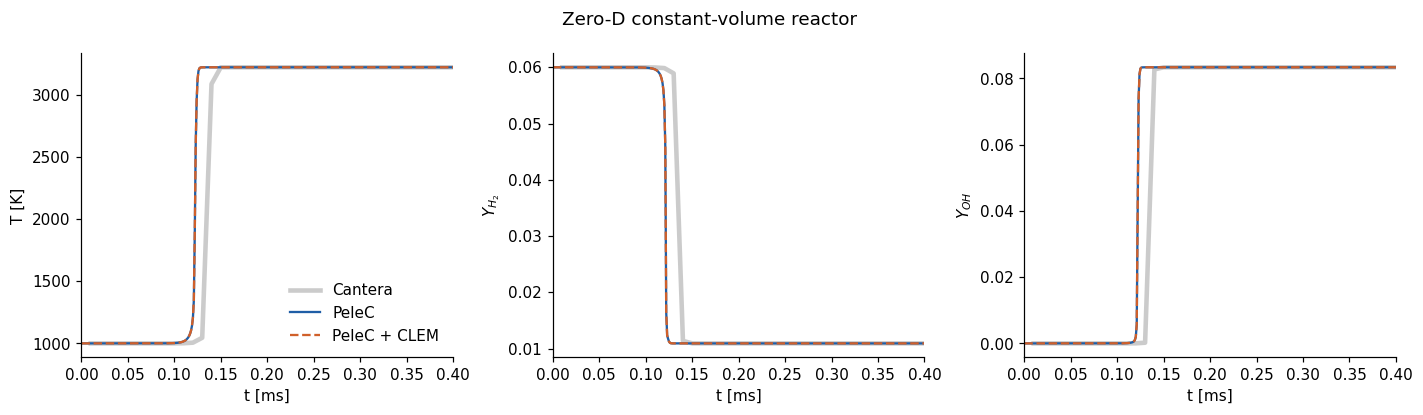

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, (v, col, label) in zip(axes, [("Temp", 1, "T [K]"), ("H2", 2, r"$Y_{H_2}$"), ("OH", 4, r"$Y_{OH}$")]):
    ax.plot(ref[:, 0] * 1e3, ref[:, col], "-", color=C_REF, lw=3, alpha=0.5, label="Cantera")
    ax.plot(zp[v][:, 0] * 1e3, zp[v][:, 1], "-", color=C_PELEC, label="PeleC")
    ax.plot(zc[v][:, 0] * 1e3, zc[v][:, 1], "--", color=C_CLEM, label="PeleC + CLEM")
    ax.set_xlabel("t [ms]"); ax.set_ylabel(label); ax.set_xlim(0, 0.4)
axes[0].legend(frameon=False)
fig.suptitle("Zero-D constant-volume reactor")
plt.tight_layout(); plt.show()

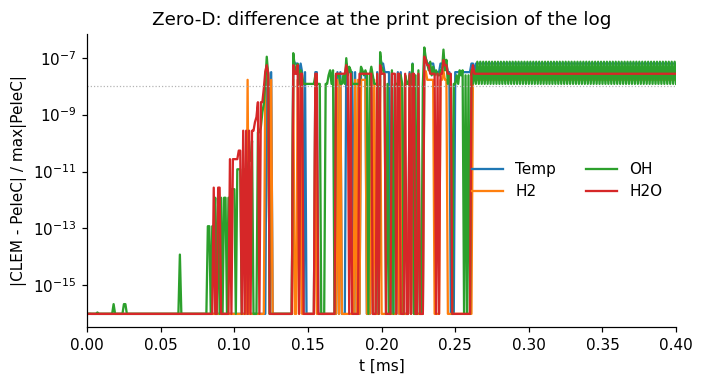

In [6]:
# the difference itself, relative to the PeleC value
fig, ax = plt.subplots(figsize=(6.5, 3.6))
for v in ["Temp", "H2", "OH", "H2O"]:
    p, c = zp[v], zc[v]
    n = min(len(p), len(c))
    ax.semilogy(p[:n, 0] * 1e3, np.abs(c[:n, 1] - p[:n, 1]) / np.abs(p[:n, 1]).max() + 1e-16, label=v)
ax.axhline(1e-8, color="0.7", lw=0.8, ls=":")
ax.set_xlabel("t [ms]"); ax.set_ylabel("|CLEM - PeleC| / max|PeleC|"); ax.set_xlim(0, 0.4)
ax.legend(frameon=False, ncol=2); ax.set_title("Zero-D: difference at the print precision of the log")
plt.tight_layout(); plt.show()

**Zero-D, what we see**

* CLEM and pure PeleC agree to ~1e-7 relative in T, p, e and every species, the last digits the log prints;
  ρ is identical and ΣY − 1 stays at round-off. Both ignite at 0.1213 ms.
* Both share the same ~11 µs offset from the Cantera file and reach its equilibrium (3223.85 K), so the
  offset is not CLEM's (the reference is also sampled only every 10 µs).
* Cost: one CVODE context per rank reused for every element; 768 elements × 6 RHS evaluations per step.

## 2. Premixed flame (stabilized, quasi-1-D)

The CLEMNew test `CLEM1DFlame`, rebuilt on this code: H₂/air φ = 0.4, 1 atm, Tᵤ = 298 K, LiDryer;
2-D 256 × 4 cells over 0.8 cm × 0.0125 cm (dx = 31 µm), inflow `Hard` at S_L, outflow `FOExtrap`,
transverse periodic. The whole domain starts from the reference flame
(`LiDryer_H2_p1_phi0_4000tu0300.dat`), the front at x = 0.35 cm; full transport in the LES;
`cfl = 0.25`; 1000 steps (t = 10.3 µs), plotfiles every 250 steps.

Three runs:

* **PeleC**: no model.
* **PeleC + CLEM**: species frozen in the LES (J_k and h_k J_k dropped), species and chemistry on the lines.
* **PeleC, no species diffusion** (`pelec.diffuse_spec = 0`): a diagnostic run, to see how much of the
  CLEM difference is the inter-cell species diffusion the CLEM step does not have yet.

In [7]:
runs = {"PeleC": ("pelec", C_PELEC, "-"),
        "PeleC + CLEM": ("clem", C_CLEM, "--"),
        "PeleC, no species diffusion": ("nospec", C_NOSPEC, ":")}
series = {label: read_series(PMF / d) for label, (d, _, _) in runs.items()}


def front(x, T):
    """x where T crosses the mid temperature, from the cold side."""
    T_mid = 0.5 * (T.min() + T.max())
    i = np.argmax(T > T_mid)
    return x[i - 1] + (T_mid - T[i - 1]) * (x[i] - x[i - 1]) / (T[i] - T[i - 1])


def thickness(x, T):
    return (T.max() - T.min()) / np.max(np.abs(np.gradient(T, x)))


print(f"{'run':30s} {'t [us]':>8s} {'x_front [cm]':>13s} {'delta_th [cm]':>14s} {'T_max':>8s} {'Y_OH max':>10s}")
for label, ser in series.items():
    for t, x, f in ser:
        T = f["Temp"]
        print(f"{label:30s} {t*1e6:8.3f} {front(x, T):13.6f} {thickness(x, T):14.6e} {T.max():8.2f} {f['Y(OH)'].max():10.4e}")

run                              t [us]  x_front [cm]  delta_th [cm]    T_max   Y_OH max
PeleC                             0.000      0.353229   6.183513e-02  1425.96 1.3809e-03
PeleC                             2.526      0.353226   6.181321e-02  1425.95 1.3809e-03
PeleC                             5.109      0.353223   6.179129e-02  1425.95 1.3808e-03
PeleC                             7.693      0.353220   6.176991e-02  1425.94 1.3807e-03
PeleC                            10.277      0.353219   6.174905e-02  1425.94 1.3806e-03
PeleC + CLEM                      0.000      0.353229   6.183513e-02  1425.96 1.3809e-03
PeleC + CLEM                      2.526      0.353244   6.183759e-02  1425.95 1.3876e-03
PeleC + CLEM                      5.109      0.353282   6.184744e-02  1425.94 1.3879e-03
PeleC + CLEM                      7.693      0.353334   6.188793e-02  1425.93 1.3860e-03
PeleC + CLEM                     10.277      0.353397   6.196268e-02  1425.92 1.3793e-03
PeleC, no species dif

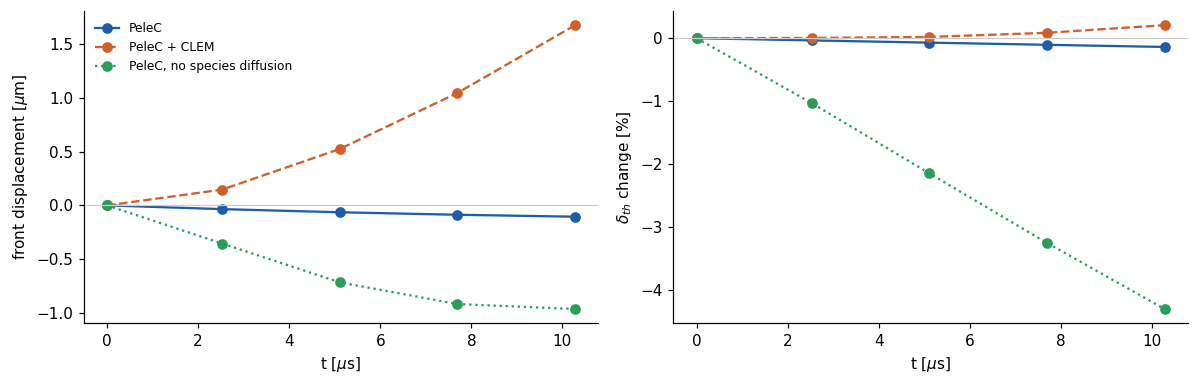

In [8]:
# front position and thickness in time
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for label, ser in series.items():
    _, color, ls = runs[label]
    t = np.array([s[0] for s in ser]) * 1e6
    xf = np.array([front(s[1], s[2]["Temp"]) for s in ser])
    th = np.array([thickness(s[1], s[2]["Temp"]) for s in ser])
    axes[0].plot(t, (xf - xf[0]) * 1e4, ls, marker="o", color=color, label=label)
    axes[1].plot(t, (th / th[0] - 1) * 1e2, ls, marker="o", color=color, label=label)
axes[0].set_ylabel(r"front displacement [$\mu$m]"); axes[1].set_ylabel(r"$\delta_{th}$ change [%]")
for ax in axes:
    ax.set_xlabel(r"t [$\mu$s]"); ax.axhline(0, color="0.8", lw=0.8)
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

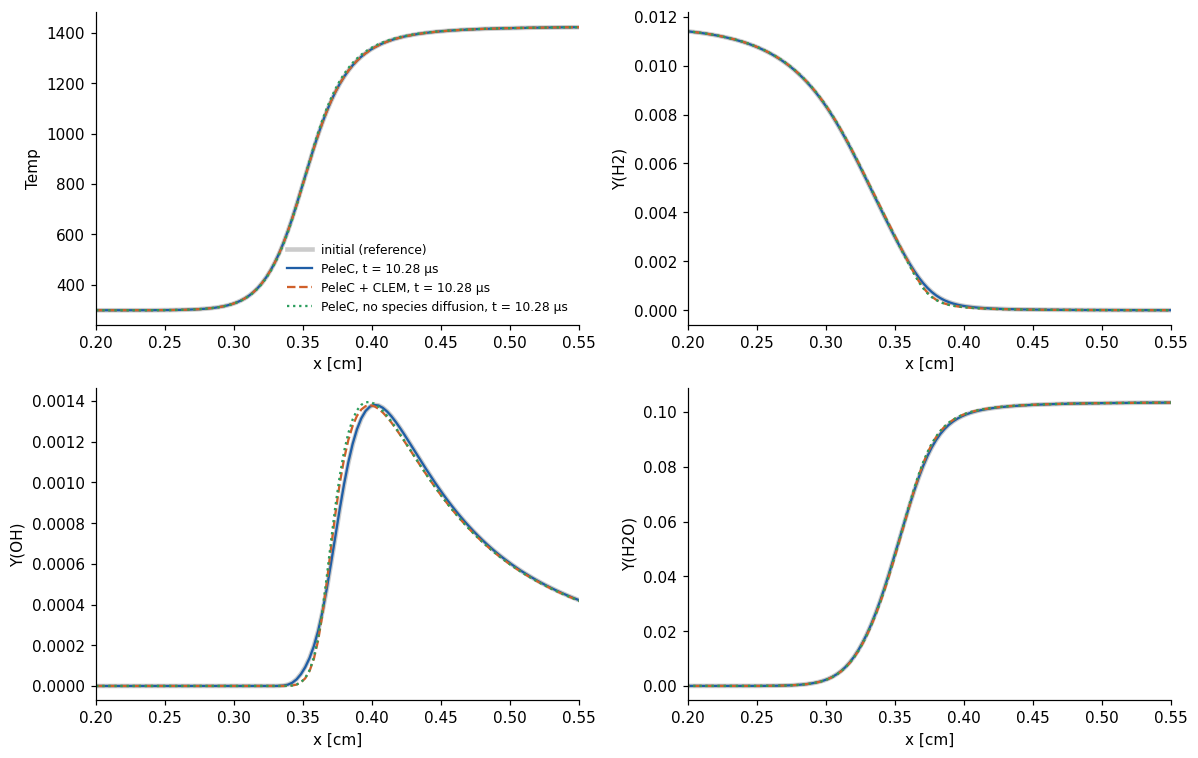

In [9]:
# profiles at the last output
t0, x, f0 = series["PeleC"][0]
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, v in zip(axes.flat, ["Temp", "Y(H2)", "Y(OH)", "Y(H2O)"]):
    ax.plot(x, f0[v], "-", color=C_REF, lw=3, alpha=0.5, label="initial (reference)")
    for label, ser in series.items():
        _, color, ls = runs[label]
        t, _, f = ser[-1]
        ax.plot(x, f[v], ls, color=color, label=f"{label}, t = {t*1e6:.2f} µs")
    ax.set_xlim(0.2, 0.55); ax.set_xlabel("x [cm]"); ax.set_ylabel(v)
axes[0, 0].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

variable  |CLEM - PeleC|  |no-spec - PeleC|  |CLEM - no-spec|   (relative to max|PeleC|)
Temp           2.291e-03          8.236e-03         8.012e-03
Y(H2)          1.659e-02          1.880e-02         3.690e-03
Y(OH)          9.052e-02          1.172e-01         2.665e-02


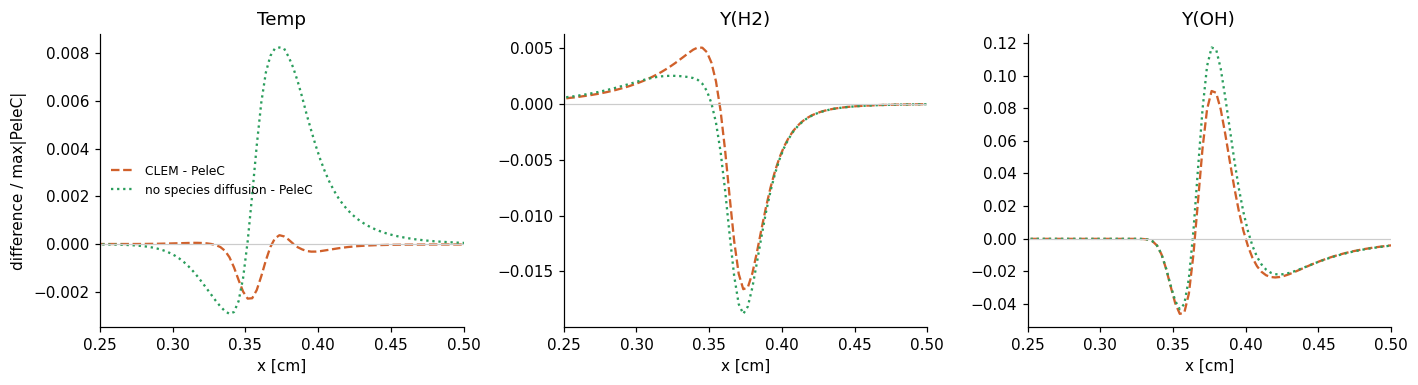

In [10]:
# differences from PeleC at the last output, relative to the PeleC maximum
_, x, fp = series["PeleC"][-1]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
print(f"{'variable':8s} {'|CLEM - PeleC|':>15s} {'|no-spec - PeleC|':>18s} {'|CLEM - no-spec|':>17s}   (relative to max|PeleC|)")
for ax, v in zip(axes, ["Temp", "Y(H2)", "Y(OH)"]):
    scale = np.abs(fp[v]).max()
    fc, fn = series["PeleC + CLEM"][-1][2], series["PeleC, no species diffusion"][-1][2]
    ax.plot(x, (fc[v] - fp[v]) / scale, "--", color=C_CLEM, label="CLEM - PeleC")
    ax.plot(x, (fn[v] - fp[v]) / scale, ":", color=C_NOSPEC, label="no species diffusion - PeleC")
    ax.set_xlim(0.25, 0.5); ax.set_xlabel("x [cm]"); ax.set_title(v); ax.axhline(0, color="0.8", lw=0.8)
    print(f"{v:8s} {np.abs(fc[v]-fp[v]).max()/scale:15.3e} {np.abs(fn[v]-fp[v]).max()/scale:18.3e} "
          f"{np.abs(fc[v]-fn[v]).max()/scale:17.3e}")
axes[0].set_ylabel("difference / max|PeleC|"); axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

run time w/o init: PeleC 5.8 s, PeleC + CLEM 167.5 s
diffusion sub-steps per line: mean 3.71, max 6
element sub-steps reacted per step: 45629, RHS evaluations per element 6.00


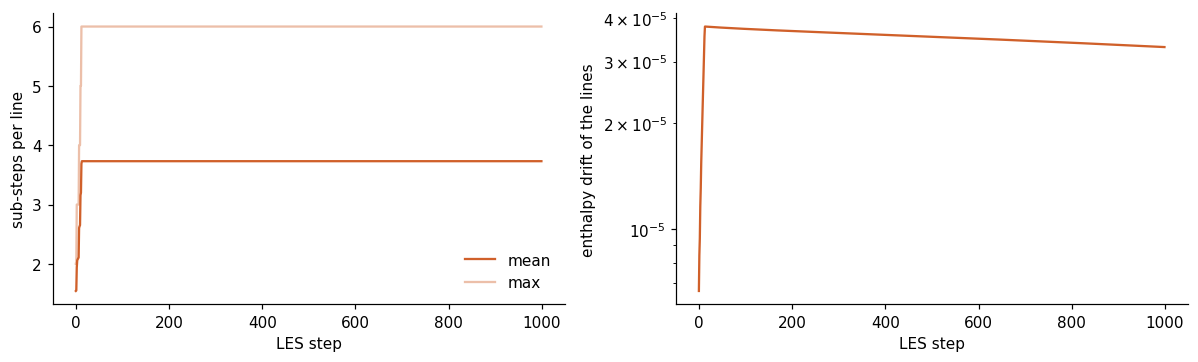

In [11]:
# cost and the CLEM line diagnostics
sub, drift, rhs = clem_diagnostics(PMF / "clem" / "run.log")
print(f"run time w/o init: PeleC {run_time(PMF / 'pelec' / 'run.log'):.1f} s, "
      f"PeleC + CLEM {run_time(PMF / 'clem' / 'run.log'):.1f} s")
print(f"diffusion sub-steps per line: mean {sub[:, 0].mean():.2f}, max {int(sub[:, 1].max())}")
print(f"element sub-steps reacted per step: {rhs[:, 0].mean():.0f}, RHS evaluations per element {rhs[:, 1].mean():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].plot(sub[:, 0], color=C_CLEM, label="mean"); axes[0].plot(sub[:, 1], color=C_CLEM, alpha=0.4, label="max")
axes[0].set_xlabel("LES step"); axes[0].set_ylabel("sub-steps per line"); axes[0].legend(frameon=False)
axes[1].semilogy(np.maximum(drift, 1e-16), color=C_CLEM)
axes[1].set_xlabel("LES step"); axes[1].set_ylabel("enthalpy drift of the lines")
plt.tight_layout(); plt.show()

**Premixed flame, what we see**

* T agrees to 0.2 %; the species differ more: up to 1.7 % in Y_H2 and 9 % in Y_OH, behind the front, where
  the leading edge of OH is steeper with CLEM.
* Most of the species difference is the missing **inter-cell species diffusion**: pure PeleC without it is off
  by about the same amount (1.9 % in Y_H2, 12 % in Y_OH), with the same shape in x, and CLEM sits much closer to
  that run (0.4 % and 2.7 %). Across one cell dx²/D ≈ 10 µs, the length of the run, so the effect shows at once.
* The temperature structure is a different story: without species diffusion PeleC thins the flame by 4 % in 10 µs
  and shifts T by 0.8 %, while CLEM keeps δ_th within 0.2 % and T within 0.2 % of PeleC. So CLEM is not simply
  "PeleC without species diffusion" in its thermal structure.
* The **front drift** is not that: without species diffusion PeleC moves the front slightly upstream, CLEM moves it
  downstream, faster with each output. Candidates: the pressure effect left for later (the enthalpy drift rises
  to ~3e-5 once the lines take several sub-steps) and the splicing at this inflow.
* Cost: about 29× pure PeleC; 3.7 diffusion sub-steps per line on average, each reacting all 12 elements
  (~46 000 CVODE calls per step, 6 RHS evaluations each).
* 10 µs is about 0.4 % of the flame time δ/S_L ≈ 2.7 ms: this tests whether CLEM keeps a correct flame in place
  over a short time, not the flame speed.